# PowerCo Customer Churn Analysis

BCG X Data Science job simulation on Forage.

**Business question:** How can customer characteristics and historical pricing information help investigate churn and prepare a customer-retention model?

This notebook consolidates customer/pricing exploration, the supplied pricing-feature example and preparation of a held-out classification dataset.

## Contents
0. Environment and data paths
1. Data understanding and quality checks
2. Exploratory analysis
3. Feature engineering
4. Model-ready data and train/test split
5. Modeling status and summary


## Part 0: Environment and data paths

Use the original authorized simulation datasets. Place the four CSV files listed below in the local `data` folder; the repository does not redistribute them.


In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

sns.set(color_codes=True)
CLIENT_PATH = DATA_DIR / "client_data.csv"
PRICE_PATH = DATA_DIR / "price_data.csv"
CLEAN_PATH = DATA_DIR / "clean_data_after_eda.csv"
MODEL_PATH = DATA_DIR / "data_for_predictions.csv"
for path in [CLIENT_PATH, PRICE_PATH, CLEAN_PATH, MODEL_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required simulation dataset is not available: {path.name}")

from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")


## Part 1: Data understanding and quality checks

The customer table contains customer attributes and a binary churn outcome. The pricing table contains repeated price observations by customer and date. Their observation units differ, so they are inspected separately before aggregation.


In [2]:
client_df = pd.read_csv(CLIENT_PATH)
price_df = pd.read_csv(PRICE_PATH)
pd.DataFrame({
    "dataset": ["customers", "prices"],
    "rows": [len(client_df), len(price_df)],
    "columns": [client_df.shape[1], price_df.shape[1]],
})


     dataset    rows  columns
0  customers   14606       26
1     prices  193002        8

In [3]:
client_df.info()
price_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  object 
 1   channel_sales                   14606 non-null  object 
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  object 
 6   date_end                        14606 non-null  object 
 7   date_modif_prod                 14606 non-null  object 
 8   date_renewal                    14606 non-null  object 
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year              14606 non-null  int64  
 11  forecast_discount_energy        14606 non-null  float64
 12  forecast_meter_rent_12m         

In [4]:
quality_summary = pd.DataFrame({
    "customer_missing_values": client_df.isna().sum(),
    "price_missing_values": price_df.isna().sum(),
}).fillna(0).astype(int)
quality_summary


                                customer_missing_values  price_missing_values
channel_sales                                         0                     0
churn                                                 0                     0
cons_12m                                              0                     0
cons_gas_12m                                          0                     0
cons_last_month                                       0                     0
date_activ                                            0                     0
date_end                                              0                     0
date_modif_prod                                       0                     0
date_renewal                                          0                     0
forecast_cons_12m                                     0                     0
forecast_cons_year                                    0                     0
forecast_discount_energy                              0         

In [5]:
client_df.describe()


           cons_12m  cons_gas_12m  cons_last_month  forecast_cons_12m  \
count  1.460600e+04  1.460600e+04     14606.000000       14606.000000   
mean   1.592203e+05  2.809238e+04     16090.269752        1868.614880   
std    5.734653e+05  1.629731e+05     64364.196422        2387.571531   
min    0.000000e+00  0.000000e+00         0.000000           0.000000   
25%    5.674750e+03  0.000000e+00         0.000000         494.995000   
50%    1.411550e+04  0.000000e+00       792.500000        1112.875000   
75%    4.076375e+04  0.000000e+00      3383.000000        2401.790000   
max    6.207104e+06  4.154590e+06    771203.000000       82902.830000   

       forecast_cons_year  forecast_discount_energy  forecast_meter_rent_12m  \
count        14606.000000              14606.000000             14606.000000   
mean          1399.762906                  0.966726                63.086871   
std           3247.786255                  5.108289                66.165783   
min              0.000

In [6]:
price_df.describe()


       price_off_peak_var  price_peak_var  price_mid_peak_var  \
count       193002.000000   193002.000000       193002.000000   
mean             0.141027        0.054630            0.030496   
std              0.025032        0.049924            0.036298   
min              0.000000        0.000000            0.000000   
25%              0.125976        0.000000            0.000000   
50%              0.146033        0.085483            0.000000   
75%              0.151635        0.101673            0.072558   
max              0.280700        0.229788            0.114102   

       price_off_peak_fix  price_peak_fix  price_mid_peak_fix  
count       193002.000000   193002.000000       193002.000000  
mean            43.334477       10.622875            6.409984  
std              5.410297       12.841895            7.773592  
min              0.000000        0.000000            0.000000  
25%             40.728885        0.000000            0.000000  
50%             44.266930     

## Part 2: Exploratory analysis

Describe the churn distribution and consumption patterns. These comparisons are descriptive; they do not establish a causal effect of price changes on churn.


In [7]:
def plot_stacked_bars(dataframe, title_, size_=(18, 10), rot_=0, legend_="upper right"):
    """
    Plot stacked bars with annotations
    """
    ax = dataframe.plot(
        kind="bar",
        stacked=True,
        figsize=size_,
        rot=rot_,
        title=title_
    )

    # Annotate bars
    annotate_stacked_bars(ax, textsize=14)
    # Rename legend
    plt.legend(["Retention", "Churn"], loc=legend_)
    # Labels
    plt.ylabel("Company base (%)")
    plt.show()

def annotate_stacked_bars(ax, pad=0.99, colour="white", textsize=13):
    """
    Add value annotations to the bars
    """

    # Iterate over the plotted rectanges/bars
    for p in ax.patches:

        # Calculate annotation
        value = str(round(p.get_height(),1))
        # If value is 0 do not annotate
        if value == '0.0':
            continue
        ax.annotate(
            value,
            ((p.get_x()+ p.get_width()/2)*pad-0.05, (p.get_y()+p.get_height()/2)*pad),
            color=colour,
            size=textsize
        )

def plot_distribution(dataframe, column, ax, bins_=50):
    """
    Plot variable distirbution in a stacked histogram of churned or retained company
    """
    # Create a temporal dataframe with the data to be plot
    temp = pd.DataFrame({"Retention": dataframe[dataframe["churn"]==0][column],
    "Churn":dataframe[dataframe["churn"]==1][column]})
    # Plot the histogram
    temp[["Retention","Churn"]].plot(kind='hist', bins=bins_, ax=ax, stacked=True)
    # X-axis label
    ax.set_xlabel(column)
    # Change the x-axis to plain style
    ax.ticklabel_format(style='plain', axis='x')


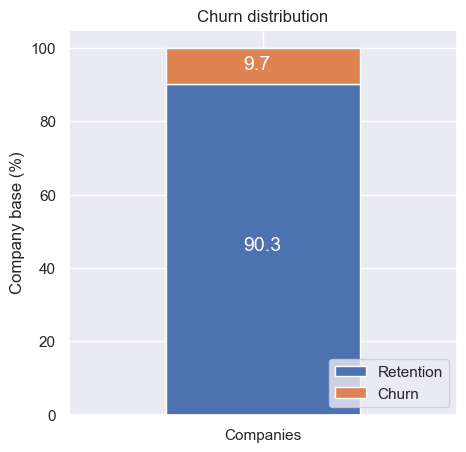

In [8]:
churn = client_df[["id", "churn"]].copy()
churn.columns = ["Companies", "churn"]
churn_total = churn.groupby("churn").count()
churn_percentage = churn_total / churn_total.sum() * 100
plot_stacked_bars(churn_percentage.transpose(), "Churn distribution", (5, 5), legend_="lower right")


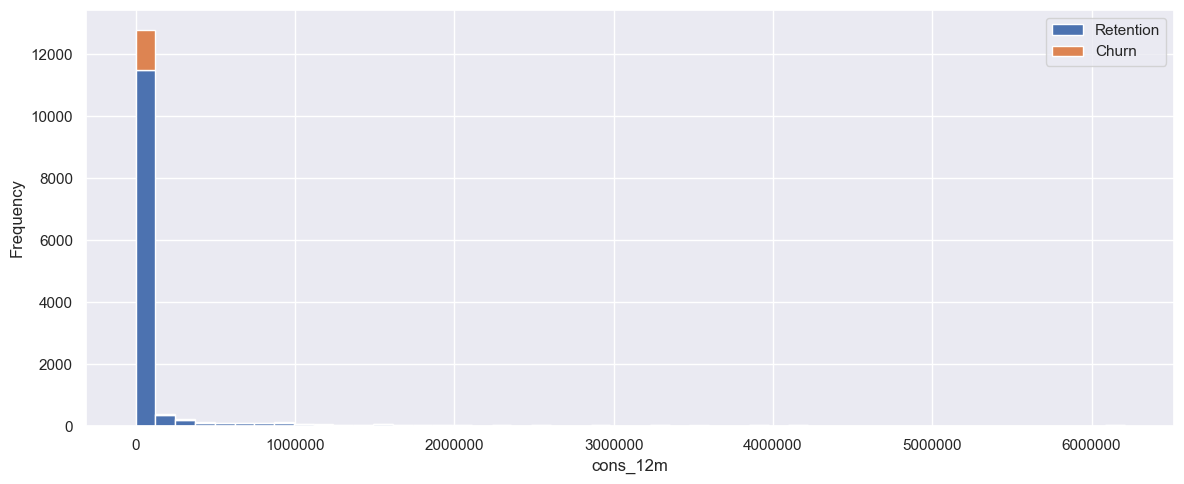

In [9]:
consumption = client_df[["id", "cons_12m", "cons_gas_12m", "cons_last_month", "imp_cons", "has_gas", "churn"]]
fig, ax = plt.subplots(figsize=(12, 5))
plot_distribution(consumption, "cons_12m", ax)
plt.tight_layout()
plt.show()


## Part 3: Feature engineering

The saved Task 3 includes a provided example that measures the difference between the last and first observed off-peak prices for each customer. This is intended to capture December-versus-January pricing changes when those months are present. The cleaned customer file is a separate input supplied for this stage.

The model-ready file in Part 4 already contains additional engineered variables. The example below is not presented as the code that created all those variables.


In [10]:
feature_df = pd.read_csv(CLEAN_PATH)
date_columns = ["date_activ", "date_end", "date_modif_prod", "date_renewal"]
for column in date_columns:
    feature_df[column] = pd.to_datetime(feature_df[column], format="%Y-%m-%d")
price_df["price_date"] = pd.to_datetime(price_df["price_date"], format="%Y-%m-%d")


In [11]:
# Group off-peak prices by companies and month
monthly_price_by_id = price_df.groupby(['id', 'price_date']).agg({'price_off_peak_var': 'mean', 'price_off_peak_fix': 'mean'}).reset_index()

# Get january and december prices
jan_prices = monthly_price_by_id.groupby('id').first().reset_index()
dec_prices = monthly_price_by_id.groupby('id').last().reset_index()

# Calculate the difference
diff = pd.merge(dec_prices.rename(columns={'price_off_peak_var': 'dec_1', 'price_off_peak_fix': 'dec_2'}), jan_prices.drop(columns='price_date'), on='id')
diff['offpeak_diff_dec_january_energy'] = diff['dec_1'] - diff['price_off_peak_var']
diff['offpeak_diff_dec_january_power'] = diff['dec_2'] - diff['price_off_peak_fix']
diff = diff[['id', 'offpeak_diff_dec_january_energy','offpeak_diff_dec_january_power']]
diff.drop(columns="id").describe()


       offpeak_diff_dec_january_energy  offpeak_diff_dec_january_power
count                     16096.000000                    16096.000000
mean                         -0.004545                        0.279544
std                           0.012778                        1.432820
min                          -0.148477                      -44.266931
25%                          -0.008161                        0.000004
50%                          -0.005610                        0.162916
75%                          -0.003573                        0.177779
max                           0.168958                       40.728885

## Part 4: Model-ready data and train/test split

Load the supplied model-ready feature table, separate the churn target from the predictors and reserve 25% of observations for testing. This retains the split used in the saved modeling notebook.


In [12]:
model_df = pd.read_csv(MODEL_PATH)
model_df = model_df.drop(columns=["Unnamed: 0"], errors="ignore")
y = model_df["churn"]
X = model_df.drop(columns=["id", "churn"])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
pd.DataFrame({"split": ["train", "test"], "rows": [len(X_train), len(X_test)], "features": [X_train.shape[1], X_test.shape[1]]})


   split   rows  features
0  train  10954        61
1   test   3652        61

## Part 5: Modeling status and summary

Random Forest is the specified classifier. The supplied saved file includes the train/test split and model specification; completed fitting, predictions and evaluation are pending in that source version.


In [13]:
model = RandomForestClassifier()
print("Model specified: RandomForestClassifier. Training and evaluation are not present in the supplied saved files.")


Model specified: RandomForestClassifier. Training and evaluation are not present in the supplied saved files.


### Summary

The workflow describes customer and pricing data, visualizes churn and consumption patterns, constructs the pricing-change example and prepares a 75/25 train/test split. When the completed modeling work is available, this section can summarize precision, recall, F1 and ROC-AUC together with the resulting retention recommendations.
